In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

In [5]:
df_master = pd.read_csv('Customer_Master_Data.csv')
df_transactions = pd.read_csv('Customer_Transactions.csv')

print("Customer Master Data:")
display(df_master.head())

print("\nCustomer Transactions Data:")
display(df_transactions.head())

Customer Master Data:


,CustomerID,Name,Email,Gender,Age,City,MaritalStatus,NumChildren,JoinDate
0,CUST10000,Onkar Bhargava,pkeer@yahoo.com,Male,54,Delhi,Divorced,0,2021-02-22
1,CUST10001,Divit Kohli,mkalita@sarin.com,Female,48,Kolkata,Married,0,2023-12-06
2,CUST10002,Kiara Behl,apteanay@hotmail.com,Male,75,Kolkata,Widowed,2,2023-08-23
3,CUST10003,Vaibhav Sankar,bseshadri@choudhry.info,Male,62,Pune,Divorced,2,2022-11-17
4,CUST10004,Shray D’Alia,bdhillon@toor-mall.com,Male,55,Delhi,Divorced,0,2022-12-04



Customer Transactions Data:


,CustomerID,TransactionDate,TransactionAmount
0,CUST10771,7/31/23,2383.07
1,CUST10100,3/10/24,497.54
2,CUST10031,2/17/25,536.78
3,CUST10987,7/17/23,314.89
4,CUST10831,12/15/24,2543.19


In [6]:
print("=== Customer Master Info ===")
df_master.info()

print("\n=== Customer Transactions Info ===")
df_transactions.info()

=== Customer Master Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     1000 non-null   object
 1   Name           1000 non-null   object
 2   Email          1000 non-null   object
 3   Gender         1000 non-null   object
 4   Age            1000 non-null   int64 
 5   City           1000 non-null   object
 6   MaritalStatus  1000 non-null   object
 7   NumChildren    1000 non-null   int64 
 8   JoinDate       1000 non-null   object
dtypes: int64(2), object(7)
memory usage: 70.4+ KB

=== Customer Transactions Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23050 entries, 0 to 23049
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         23050 non-null  object 
 1   TransactionDate    23050 non-null  object 
 2   T

In [7]:
df_master['JoinDate'] = pd.to_datetime(df_master['JoinDate'])
df_transactions['TransactionDate'] = pd.to_datetime(df_transactions['TransactionDate'])

print("df_master 'JoinDate' type:", df_master['JoinDate'].dtype)
print("df_transactions 'TransactionDate' type:", df_transactions['TransactionDate'].dtype)

/tmp/ipykernel_1501/1723067505.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_transactions['TransactionDate'] = pd.to_datetime(df_transactions['TransactionDate'])


df_master 'JoinDate' type: datetime64[ns]
df_transactions 'TransactionDate' type: datetime64[ns]


In [8]:
gender_counts = df_master['Gender'].value_counts()
display(gender_counts)

,count
Gender,
Female,340
Male,332
Not Disclosed,328


In [9]:
initial_count = len(df_transactions)
valid_customer_ids = df_master['CustomerID'].unique()

df_transactions_filtered = df_transactions[df_transactions['CustomerID'].isin(valid_customer_ids)].copy()
final_count = len(df_transactions_filtered)

print(f"Original transactions count: {initial_count}")
print(f"Filtered transactions count: {final_count}")
print(f"Removed transactions count: {initial_count - final_count}")

# Overwrite the original variable or proceed with df_transactions_filtered
df_transactions = df_transactions_filtered
display(df_transactions.head())

Original transactions count: 23050
Filtered transactions count: 23050
Removed transactions count: 0


,CustomerID,TransactionDate,TransactionAmount
0,CUST10771,2023-07-31,2383.07
1,CUST10100,2024-03-10,497.54
2,CUST10031,2025-02-17,536.78
3,CUST10987,2023-07-17,314.89
4,CUST10831,2024-12-15,2543.19


In [10]:
# Join df_master with df_transactions on CustomerID
df_merged = pd.merge(df_transactions, df_master, on='CustomerID', how='inner')

print(f"Merged DataFrame shape: {df_merged.shape}")
display(df_merged.head(15))

Merged DataFrame shape: (23050, 11)


,CustomerID,TransactionDate,TransactionAmount,Name,Email,Gender,Age,City,MaritalStatus,NumChildren,JoinDate
0,CUST10771,2023-07-31,2383.07,Lakshay Dhillon,dharmajantara@gmail.com,Female,27,Ahmedabad,Widowed,3,2023-05-31
1,CUST10100,2024-03-10,497.54,Aniruddh Borah,jivikabhavsar@gmail.com,Female,53,Lucknow,Divorced,4,2022-01-08
2,CUST10031,2025-02-17,536.78,Ritvik Ahuja,jhaverifarhan@chandra.org,Male,40,Ahmedabad,Single,0,2023-12-03
3,CUST10987,2023-07-17,314.89,Jayan Wagle,ojas82@gmail.com,Not Disclosed,75,Bangalore,Widowed,4,2022-03-18
4,CUST10831,2024-12-15,2543.19,Ishita Agarwal,vbalay@yahoo.com,Not Disclosed,27,Jaipur,Divorced,4,2021-06-30
5,CUST10404,2025-02-28,432.22,Vidur Dasgupta,riya24@yahoo.com,Not Disclosed,33,Hyderabad,Married,2,2023-02-09
6,CUST10488,2025-06-07,2178.25,Adah Raval,jkara@divan.com,Male,36,Bangalore,Single,2,2022-07-30
7,CUST10988,2025-03-25,85.46,Shamik Salvi,boasekrish@mammen.com,Not Disclosed,19,Chennai,Divorced,2,2023-09-27
8,CUST10657,2023-09-10,1800.32,Navya Boase,mallickrati@khatri.net,Not Disclosed,49,Mumbai,Widowed,3,2022-06-05
9,CUST10007,2023-12-15,305.90,Zeeshan Salvi,ira51@saini-kumar.com,Not Disclosed,32,Pune,Widowed,1,2021-08-10


In [11]:
# Ensure TransactionDate is datetime
df_transactions['TransactionDate'] = pd.to_datetime(df_transactions['TransactionDate'])

# Define the reference date (e.g., 1 day after the latest transaction in the dataset)
reference_date = df_transactions['TransactionDate'].max() + pd.Timedelta(days=1)
print(f"Reference Date for Recency: {reference_date.strftime('%Y-%m-%d')}")

# Calculate RFM metrics
df_rfm = df_transactions.groupby('CustomerID').agg(
    LastTransactionDate=('TransactionDate', 'max'),
    Frequency=('TransactionDate', 'count'),
    Monetary=('TransactionAmount', 'sum')
).reset_index()

# Compute Recency as the number of days between the last transaction and the reference date
df_rfm['Recency'] = (reference_date - df_rfm['LastTransactionDate']).dt.days

# Drop the intermediate LastTransactionDate column and reorder columns
df_rfm = df_rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary']]

display(df_rfm.head(10))

Reference Date for Recency: 2025-07-30


,CustomerID,Recency,Frequency,Monetary
0,CUST10000,13,23,21265.49
1,CUST10001,35,30,28654.31
2,CUST10002,18,24,23884.03
3,CUST10003,81,25,24206.03
4,CUST10004,8,19,25565.30
5,CUST10005,24,29,29459.82
6,CUST10006,11,28,27922.36
7,CUST10007,86,15,14957.06
8,CUST10008,3,19,19479.25
9,CUST10009,7,25,22832.83


In [12]:
df_rfm.describe()

,Recency,Frequency,Monetary
count,1000.000000,1000.000000,1000.00000
mean,50.794000,23.050000,23053.19966
std,58.124418,4.810472,5622.44101
min,1.000000,6.000000,5052.69000
25%,13.000000,20.000000,18965.46250
50%,32.000000,23.000000,22969.82000
75%,69.000000,26.000000,26827.39250
max,524.000000,38.000000,44784.99000


In [13]:
import numpy as np
import pandas as pd

# Define Recency scoring logic
def compute_recency_score(r):
    if r <= 30:
        return 5
    elif r <= 60:
        return 4
    elif r <= 120:
        return 3
    elif r <= 240:
        return 2
    else:
        return 1

# Define Frequency scoring logic
def compute_frequency_score(f):
    if f <= 7:
        return 1
    elif f <= 14:
        return 2
    elif f <= 21:
        return 3
    elif f <= 28:
        return 4
    else:
        return 5

# Define Monetary scoring logic
def compute_monetary_score(m):
    if m <= 10000:
        return 1
    elif m <= 20000:
        return 2
    elif m <= 30000:
        return 3
    elif m <= 40000:
        return 4
    else:
        return 5

# Apply the custom functions to create the score columns
df_rfm['Recency_Score'] = df_rfm['Recency'].apply(compute_recency_score)
df_rfm['Frequency_Score'] = df_rfm['Frequency'].apply(compute_frequency_score)
df_rfm['Monetary_Score'] = df_rfm['Monetary'].apply(compute_monetary_score)

# Display the updated DataFrame
display(df_rfm.head(10))

,CustomerID,Recency,Frequency,Monetary,Recency_Score,Frequency_Score,Monetary_Score
0,CUST10000,13,23,21265.49,5,4,3
1,CUST10001,35,30,28654.31,4,5,3
2,CUST10002,18,24,23884.03,5,4,3
3,CUST10003,81,25,24206.03,3,4,3
4,CUST10004,8,19,25565.30,5,3,3
5,CUST10005,24,29,29459.82,5,5,3
6,CUST10006,11,28,27922.36,5,4,3
7,CUST10007,86,15,14957.06,3,3,2
8,CUST10008,3,19,19479.25,5,3,2
9,CUST10009,7,25,22832.83,5,4,3


In [14]:
# Concatenate Recency, Frequency, and Monetary scores as string into a new column 'RFM Score'
df_rfm['RFM Score'] = (
    df_rfm['Recency_Score'].astype(str) +
    df_rfm['Frequency_Score'].astype(str) +
    df_rfm['Monetary_Score'].astype(str)
)

# Display the top 10 rows of df_rfm to verify the result
display(df_rfm.head(15))

,CustomerID,Recency,Frequency,Monetary,Recency_Score,Frequency_Score,Monetary_Score,RFM Score
0,CUST10000,13,23,21265.49,5,4,3,543
1,CUST10001,35,30,28654.31,4,5,3,453
2,CUST10002,18,24,23884.03,5,4,3,543
3,CUST10003,81,25,24206.03,3,4,3,343
4,CUST10004,8,19,25565.30,5,3,3,533
5,CUST10005,24,29,29459.82,5,5,3,553
6,CUST10006,11,28,27922.36,5,4,3,543
7,CUST10007,86,15,14957.06,3,3,2,332
8,CUST10008,3,19,19479.25,5,3,2,532
9,CUST10009,7,25,22832.83,5,4,3,543


In [15]:
def assign_segment(row):
    r = row['Recency_Score']
    f = row['Frequency_Score']
    m = row['Monetary_Score']

    # Champions: R 4-5, F 4-5, M 4-5
    if r in [4, 5] and f in [4, 5] and m in [4, 5]:
        return 'Champions'

    # Loyal Customers: F 4-5, R 2-5
    if f in [4, 5] and r in [2, 3, 4, 5]:
        return 'Loyal Customers'

    # Potential Loyalist: R 4-5, F 2-3
    if r in [4, 5] and f in [2, 3]:
        return 'Potential Loyalist'

    # At Risk: R 1-2, F 3-5
    if r in [1, 2] and f in [3, 4, 5]:
        return 'At Risk'

    # Lost: R 1, F 1-2, M 1-2
    if r == 1 and f in [1, 2] and m in [1, 2]:
        return 'Lost'

    # Big Spenders: M 4-5, F 2-3, R 3-4
    if m in [4, 5] and f in [2, 3] and r in [3, 4]:
        return 'Big Spenders'

    # Fallback for any customer who does not strictly fit above overlap groups
    return 'Others'

# Apply the segment function
df_rfm['Customer Segment'] = df_rfm.apply(assign_segment, axis=1)

# Display segment counts and head of df_rfm
print("Segment Counts:")
print(df_rfm['Customer Segment'].value_counts())
display(df_rfm.head(15))

Segment Counts:
Customer Segment
Loyal Customers       542
Potential Loyalist    248
Champions              84
Others                 77
At Risk                47
Lost                    2
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,Recency_Score,Frequency_Score,Monetary_Score,RFM Score,Customer Segment
0,CUST10000,13,23,21265.49,5,4,3,543,Loyal Customers
1,CUST10001,35,30,28654.31,4,5,3,453,Loyal Customers
2,CUST10002,18,24,23884.03,5,4,3,543,Loyal Customers
3,CUST10003,81,25,24206.03,3,4,3,343,Loyal Customers
4,CUST10004,8,19,25565.30,5,3,3,533,Potential Loyalist
5,CUST10005,24,29,29459.82,5,5,3,553,Loyal Customers
6,CUST10006,11,28,27922.36,5,4,3,543,Loyal Customers
7,CUST10007,86,15,14957.06,3,3,2,332,Others
8,CUST10008,3,19,19479.25,5,3,2,532,Potential Loyalist
9,CUST10009,7,25,22832.83,5,4,3,543,Loyal Customers


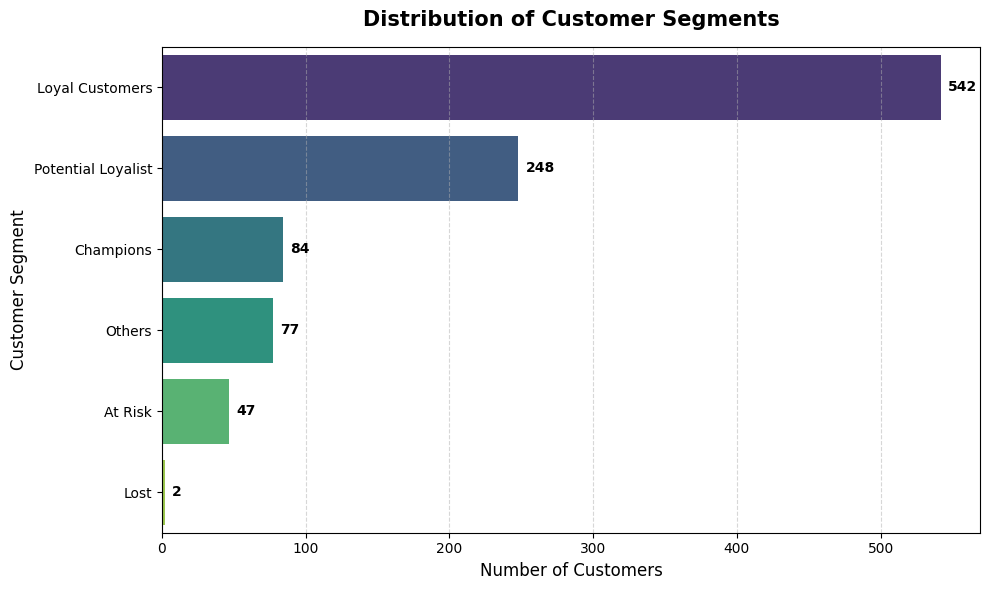

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each segment
segment_counts = df_rfm['Customer Segment'].value_counts().reset_index()
segment_counts.columns = ['Customer Segment', 'Count']

# Create a bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Count', y='Customer Segment', data=segment_counts, palette='viridis', hue='Customer Segment', legend=False)

# Add details
plt.title('Distribution of Customer Segments', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Number of Customers', fontsize=12)
plt.ylabel('Customer Segment', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Show values on the bars
for index, value in enumerate(segment_counts['Count']):
    plt.text(value + 5, index, str(value), va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Age Statistics by Customer Segment:


,count,mean,std,min,25%,50%,75%,max
Customer Segment,,,,,,,,
At Risk,47.0,45.191489,16.753505,18.0,32.00,43.0,61.00,73.0
Champions,84.0,45.333333,16.942378,19.0,31.00,45.0,59.00,75.0
Lost,2.0,51.500000,19.091883,38.0,44.75,51.5,58.25,65.0
Loyal Customers,542.0,46.892989,16.356574,18.0,33.00,46.0,61.00,75.0
Others,77.0,48.272727,17.827120,18.0,32.00,49.0,63.00,75.0
Potential Loyalist,248.0,45.576613,16.584045,18.0,30.75,44.5,58.25,75.0


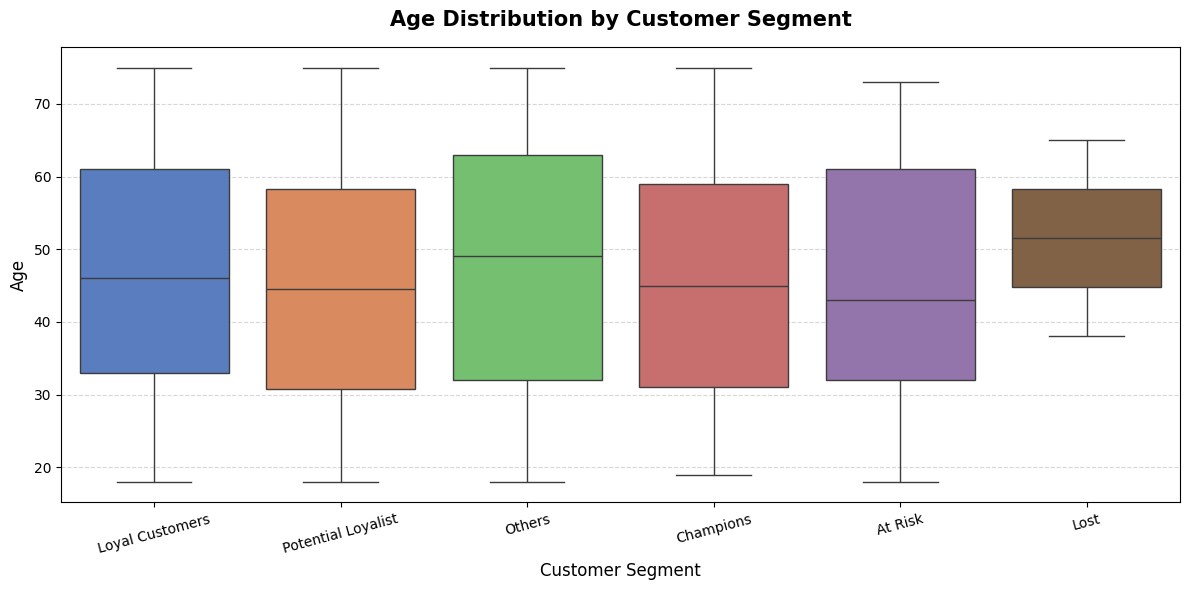

In [17]:
# Merge Age from df_master with df_rfm
df_segment_age = pd.merge(df_rfm[['CustomerID', 'Customer Segment']], df_master[['CustomerID', 'Age']], on='CustomerID', how='inner')

# Calculate basic statistics of Age for each Customer Segment
age_summary = df_segment_age.groupby('Customer Segment')['Age'].describe()
print("Age Statistics by Customer Segment:")
display(age_summary)

# Create a box plot to visualize the age brackets/distribution for each segment
plt.figure(figsize=(12, 6))
sns.boxplot(x='Customer Segment', y='Age', data=df_segment_age, palette='muted', hue='Customer Segment', legend=False)

plt.title('Age Distribution by Customer Segment', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Customer Segment', fontsize=12)
plt.ylabel('Age', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

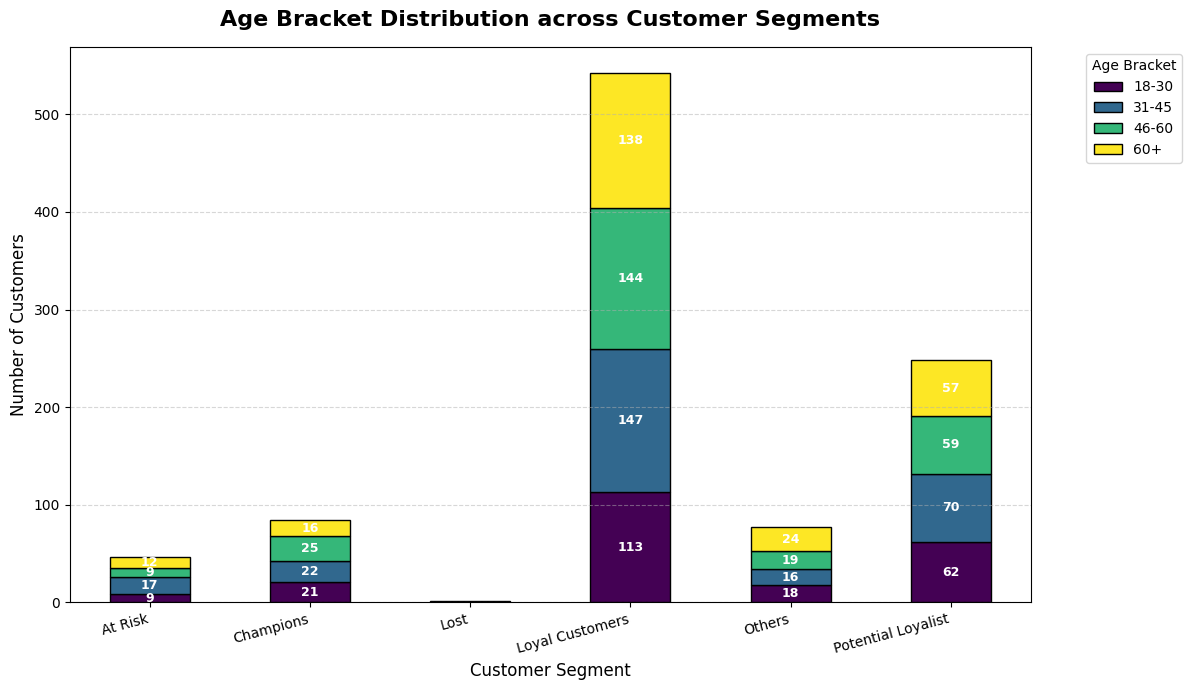

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define logical age brackets
bins = [0, 30, 45, 60, 100]
labels = ['18-30', '31-45', '46-60', '60+']

df_segment_age['Age Bracket'] = pd.cut(df_segment_age['Age'], bins=bins, labels=labels, right=True)

# Pivot data to obtain counts of each age bracket within each segment
stacked_data = df_segment_age.groupby(['Customer Segment', 'Age Bracket'], observed=False).size().unstack(fill_value=0)

# Normalize data to show percentage or plot absolute counts
# We will plot absolute counts as a stacked bar chart
ax = stacked_data.plot(kind='bar', stacked=True, figsize=(12, 7), colormap='viridis', edgecolor='black')

# Set chart details
plt.title('Age Bracket Distribution across Customer Segments', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Customer Segment', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.xticks(rotation=15, ha='right')
plt.legend(title='Age Bracket', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add exact value labels inside the stacked sections if space permits
for rect in ax.patches:
    height = rect.get_height()
    width = rect.get_width()
    x = rect.get_x()
    y = rect.get_y()
    if height > 5: # Only label if bar section is visible enough
        ax.text(x + width/2, y + height/2, int(height),
                ha='center', va='center', fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Map each CustomerID to their Age Bracket
customer_age_brackets = df_segment_age[['CustomerID', 'Age Bracket']]

# Merge with transactions to get spending information
df_spending = pd.merge(df_transactions, customer_age_brackets, on='CustomerID', how='inner')

# Calculate total spend, average transaction amount, and transaction count per age bracket
spending_summary = df_spending.groupby('Age Bracket', observed=False).agg(
    Total_Spend=('TransactionAmount', 'sum'),
    Average_Spend=('TransactionAmount', 'mean'),
    Transaction_Count=('TransactionAmount', 'count')
).reset_index()

print("Spending Analysis by Age Bracket:")
display(spending_summary)


Spending Analysis by Age Bracket:


,Age Bracket,Total_Spend,Average_Spend,Transaction_Count
0,18-30,5183940.31,1010.120871,5132
1,31-45,6364600.50,1005.148531,6332
2,46-60,5883298.49,992.961770,5925
3,60+,5621360.36,992.997767,5661


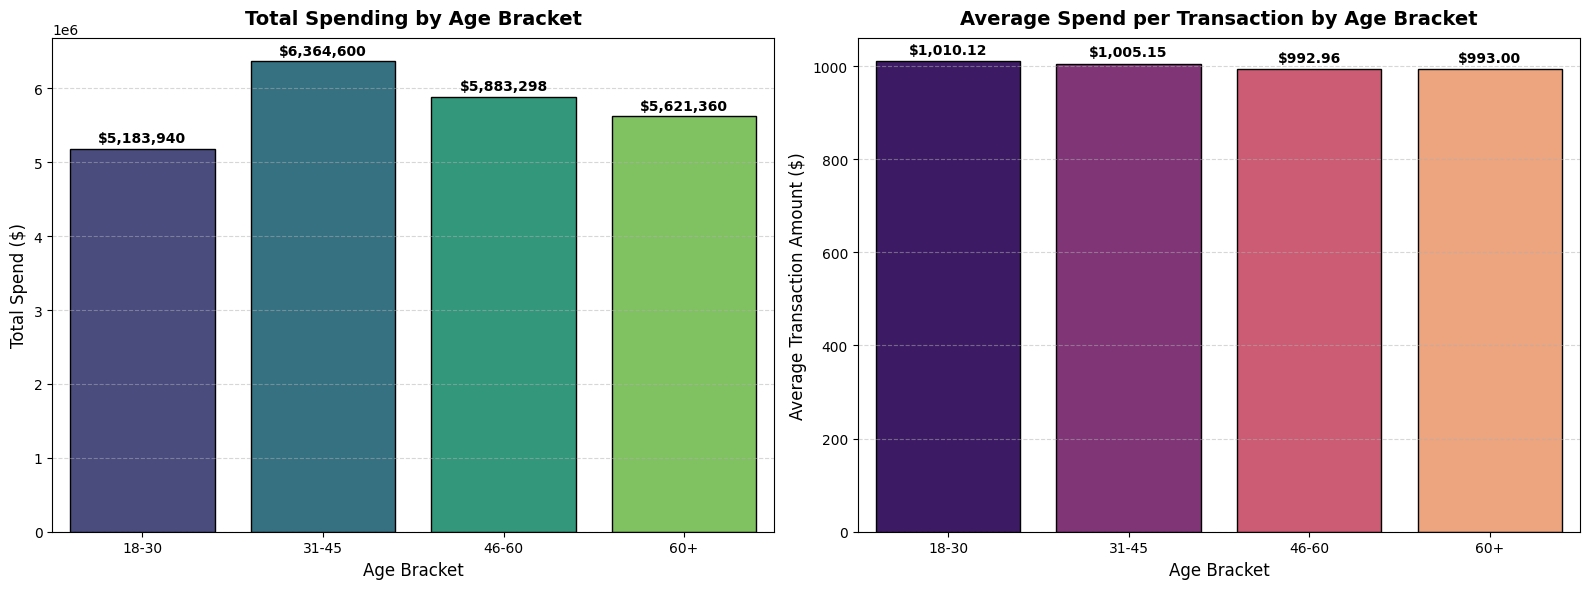

In [20]:
# Visualize total and average spending using side-by-side bar plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Total Spending per Age Bracket
sns.barplot(x='Age Bracket', y='Total_Spend', data=spending_summary, ax=axes[0], palette='viridis', hue='Age Bracket', legend=False, edgecolor='black')
axes[0].set_title('Total Spending by Age Bracket', fontsize=14, fontweight='bold', pad=10)
axes[0].set_xlabel('Age Bracket', fontsize=12)
axes[0].set_ylabel('Total Spend ($)', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Add values on top of the bars
for bar in axes[0].patches:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, height + 50000, f"${height:,.0f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Average Spend per Transaction by Age Bracket
sns.barplot(x='Age Bracket', y='Average_Spend', data=spending_summary, ax=axes[1], palette='magma', hue='Age Bracket', legend=False, edgecolor='black')
axes[1].set_title('Average Spend per Transaction by Age Bracket', fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel('Age Bracket', fontsize=12)
axes[1].set_ylabel('Average Transaction Amount ($)', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Add values on top of the bars
for bar in axes[1].patches:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 10, f"${height:,.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Map each CustomerID to their MaritalStatus
customer_marital = df_master[['CustomerID', 'MaritalStatus']]

# Merge with transactions to get spending information
df_marital_spending = pd.merge(df_transactions, customer_marital, on='CustomerID', how='inner')

# Calculate total spend, average transaction amount, and transaction count per marital status
marital_summary = df_marital_spending.groupby('MaritalStatus').agg(
    Total_Spend=('TransactionAmount', 'sum'),
    Average_Spend=('TransactionAmount', 'mean'),
    Transaction_Count=('TransactionAmount', 'count')
).reset_index().sort_values(by='Total_Spend', ascending=False)

print("Spending Analysis by Marital Status:")
display(marital_summary)

Spending Analysis by Marital Status:


,MaritalStatus,Total_Spend,Average_Spend,Transaction_Count
3,Widowed,6457754.15,1002.445537,6442
0,Divorced,5861664.88,1007.331995,5819
2,Single,5498101.28,985.676099,5578
1,Married,5235679.35,1004.736010,5211


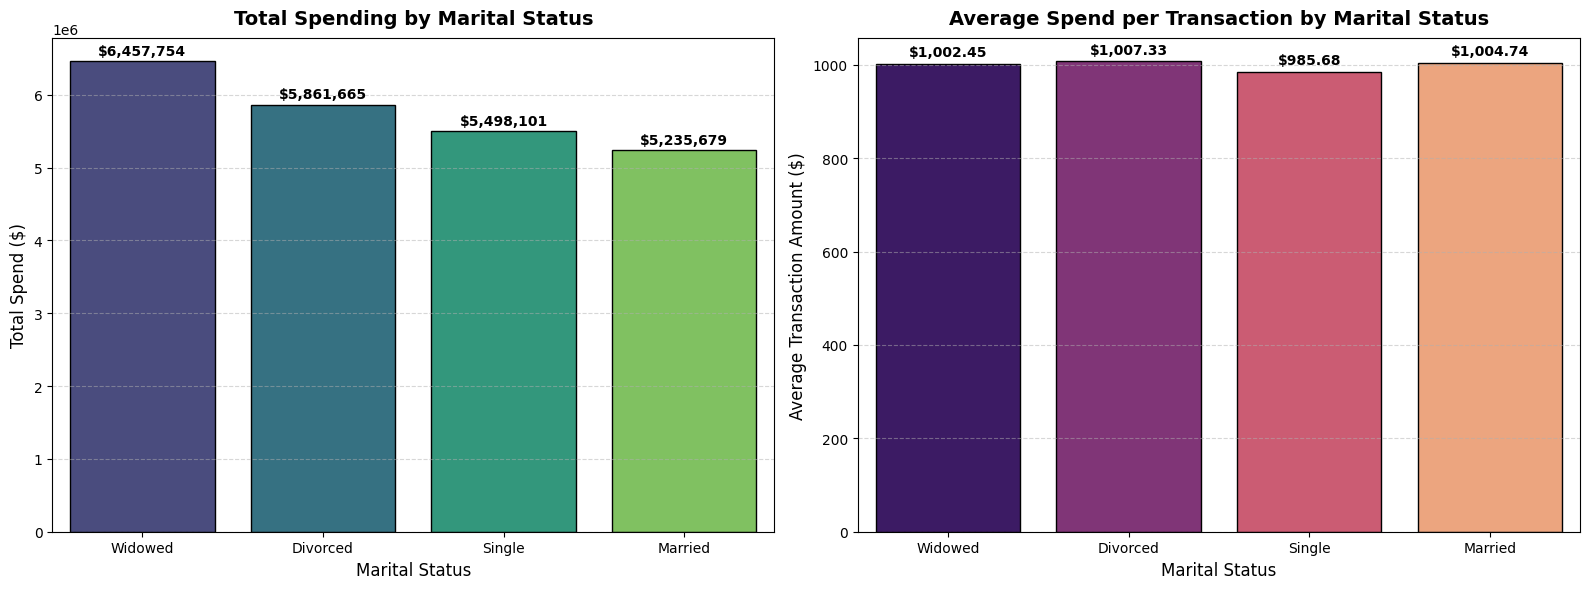

In [22]:
# Visualize the relationship between marital status and spending
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Total Spending per Marital Status
sns.barplot(x='MaritalStatus', y='Total_Spend', data=marital_summary, ax=axes[0], palette='viridis', hue='MaritalStatus', legend=False, edgecolor='black')
axes[0].set_title('Total Spending by Marital Status', fontsize=14, fontweight='bold', pad=10)
axes[0].set_xlabel('Marital Status', fontsize=12)
axes[0].set_ylabel('Total Spend ($)', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Add values on top of the bars
for bar in axes[0].patches:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, height + 50000, f"${height:,.0f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Average Spend per Transaction by Marital Status
sns.barplot(x='MaritalStatus', y='Average_Spend', data=marital_summary, ax=axes[1], palette='magma', hue='MaritalStatus', legend=False, edgecolor='black')
axes[1].set_title('Average Spend per Transaction by Marital Status', fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel('Marital Status', fontsize=12)
axes[1].set_ylabel('Average Transaction Amount ($)', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Add values on top of the bars
for bar in axes[1].patches:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 10, f"${height:,.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()